# Índice de Desarrollo Humano ajustado por la desigualdad

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"               # carpeta en research/temas/
GRAFICA_ID = "idh-desigualdad"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Índice de Desarrollo Humano ajustado por la desigualdad"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Índice de 0 a 1"
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 3               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El **Índice de Desarrollo Humano (IDH)** del Programa de las Naciones Unidas para el Desarrollo (PNUD) resume tres dimensiones de la calidad de vida: una vida larga y saludable (esperanza de vida al nacer), la educación (años de escolarización) y un nivel de vida digno (renta nacional por habitante). Va de 0 a 1. El **IDH ajustado por la desigualdad (IDH-D)** descuenta de cada dimensión lo desigual que es su reparto entre la población: si todas las personas tuvieran lo mismo, coincidiría con el IDH; cuanto más desigual es el reparto, más baja respecto a él.

**Para qué sirve.** Complementa al PIB por habitante con un indicador de calidad de vida que tiene en cuenta la salud, la educación y la desigualdad, no solo la producción media.

**Limitaciones.**
- Es un índice compuesto: la elección de las dimensiones y de cómo se combinan es del PNUD.
- El PNUD revisa toda la serie en cada edición del informe; los datos de ediciones distintas no se deben mezclar.
- La desigualdad de cada dimensión sale de encuestas distintas según el país y el año, lo que puede producir saltos de un año a otro.
- El PNUD no publica la media de la UE-27 ni de la OCDE (solo grupos por nivel de desarrollo y regiones del mundo).

## 2. Descarga

**PNUD, Informe sobre Desarrollo Humano** (fichero de las series completas de los índices compuestos de la última edición, `lib/undp.py`): IDH ajustado por la desigualdad (`ihdi`) de España, EE. UU. y Canadá; y, para las notas, el IDH (`hdi`), la pérdida por desigualdad (`loss`, en %) y la desigualdad en la esperanza de vida, la educación y la renta (`ineq_le`, `ineq_edu`, `ineq_inc`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

from datetime import date

import pandas as pd
import requests

from lib import estilos, undp
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
import json

PAISES = {"ESP": "espana", "USA": "eeuu", "CAN": "canada"}
GLOBAL = json.loads((RAIZ / "global.json").read_text(encoding="utf-8"))["paises"]
UE27 = [p["codigo"] for p in GLOBAL if "ue27" in p["grupos"]]
OCDE = [p["codigo"] for p in GLOBAL if "ocde" in p["grupos"]]
sesion = requests.Session()

df, fuentes = undp.get("ihdi", paises=PAISES, desde=DESDE, sesion=sesion)
# Todos los países de la UE-27 y la OCDE, para calcular sus medias (el PNUD no las publica)
todos, _ = undp.get("ihdi", paises={c: c for c in dict.fromkeys(UE27 + OCDE)}, desde=DESDE, sesion=sesion)
extra = {ind: undp.get(ind, paises={"ESP": "espana"}, desde=DESDE, sesion=sesion)[0].set_index("periodo")["valor"]
         for ind in ("hdi", "loss", "ineq_le", "ineq_edu", "ineq_inc")}
print(df.groupby("serie")["periodo"].agg(["min", "max", "count"]))

         min   max  count
serie                    
canada  2010  2023     14
eeuu    2010  2023     14
espana  2014  2023     10


## 3. Transformación

1. Los valores se usan tal como los publica el PNUD (índice de 0 a 1), sin transformar.
2. Las series `ue27` y `ocde` quedan en `null`: el PNUD no publica esos agregados (METODOLOGIA §2.3).
3. Para las notas: el IDH de España, la pérdida por desigualdad y la desigualdad de cada dimensión en el último año.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


tabla = todos.pivot(index="periodo", columns="serie", values="valor")
medias = {}
for serie_, miembros in (("ue27", UE27), ("ocde", OCDE)):
    # Media simple de los países, solo en los años con dato de todos
    presentes = [c for c in miembros if c in tabla.columns]
    medias[serie_] = (presentes, tabla[presentes].dropna().mean(axis=1))
    print(serie_, f"{len(presentes)}/{len(miembros)} países con dato; años:", list(medias[serie_][1].index))
df = pd.concat(
    [df, *[pd.DataFrame({"serie": s_, "periodo": m.index, "valor": m.values}) for s_, (_, m) in medias.items()]],
    ignore_index=True,
)
fuentes = [*fuentes, *[FuenteMeta(s_, undp.ORGANISMO, f"Human Development Report {undp.EDICION}: media simple de los {len(p)} países con dato, cálculo propio",
                                  undp.URL_DOCUMENTACION, HOY) for s_, (p, _) in medias.items()]]

a = int(df[df["serie"] == "espana"].dropna()["periodo"].max())
NOTAS = [
    f"PNUD, Informe sobre Desarrollo Humano {undp.EDICION}, series completas de los índices compuestos: IDH ajustado "
    "por la desigualdad (IHDI), de 0 a 1. Combina la esperanza de vida al nacer, los años de escolarización y la renta "
    "nacional bruta por habitante, cada una descontada por la desigualdad de su reparto entre la población.",
    f"España en {a}: IDH sin ajustar {es(extra['hdi'][a], 3)}; la desigualdad le resta un {es(extra['loss'][a])} %. "
    f"Desigualdad en cada dimensión (coeficiente de Atkinson, en %): esperanza de vida {es(extra['ineq_le'][a])}, "
    f"educación {es(extra['ineq_edu'][a])} y renta {es(extra['ineq_inc'][a])}.",
    "El PNUD revisa toda la serie en cada edición; los datos no se deben comparar con los de ediciones anteriores. La "
    "desigualdad de cada dimensión sale de encuestas que cambian según el país y el año.",
    "UE-27 y OCDE: el PNUD no publica esos agregados (solo grupos por nivel de desarrollo y regiones del mundo); son la "
    "media simple del IDH ajustado de los países de cada grupo, solo en los años con dato de todos ellos (cálculo propio, "
    f"sin ponderar por población): {len(medias['ue27'][0])} países de la UE-27 y {len(medias['ocde'][0])} de la OCDE.",
]


ue27 27/27 países con dato; años: [2014, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
ocde 38/38 países con dato; años: [2019, 2020, 2021, 2022, 2023]


## 4. Visualización

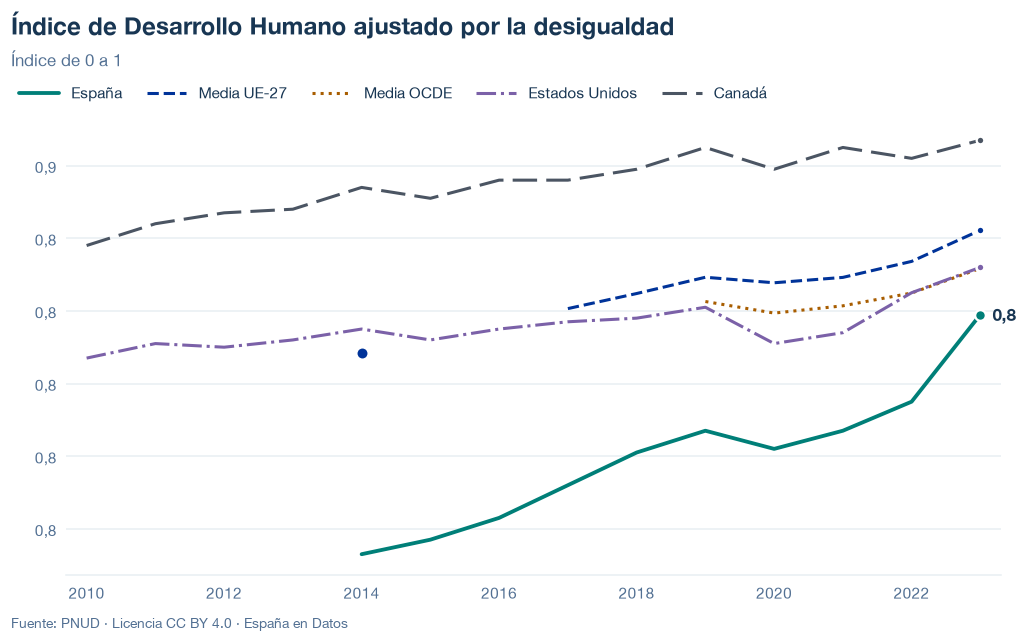

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/idh-desigualdad.json y data/idh-desigualdad.csv


## 6. Fuentes, notas y licencia

- PNUD, Informe sobre Desarrollo Humano: fichero de las series completas de los índices compuestos de la última edición (`ihdi`; `hdi`, `loss`, `ineq_le`, `ineq_edu` e `ineq_inc` para las notas), descargado con `lib/undp.py`.

La fecha de consulta de cada serie está en `fuentes` del JSON; `writer.py` añade a las notas el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.